# Greedy Agent: Results and Figures

This notebook evaluates the **Greedy** 2048 agent and produces its tables and figures for the presentation and paper.

- Greedy plays 100 seeded games (seeds 0–99), so every run reproduces the same results.
- Per-game results are cached in `experiments/results/greedy.csv`. Set `FORCE_RERUN = True` to regenerate them.
- Every figure is saved as a PNG in `experiments/figures/` for the slides.

Run it from the top: **Kernel → Restart & Run All**.

In [1]:
import math
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# Make the repo importable whether the notebook is run from experiments/ or the repo root.
REPO_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "experiments" else os.getcwd()
sys.path.insert(0, REPO_ROOT)

from agents.greedy import GreedyAgent
from agents.heuristic import DEFAULT_WEIGHTS, HeuristicWeights
from experiments.evaluate import write_csv
from game import Game, format_board, play_games

N_GAMES = 100
SEEDS = list(range(N_GAMES))
FORCE_RERUN = False

RESULTS_DIR = os.path.join(REPO_ROOT, "experiments", "results")
FIG_DIR = os.path.join(REPO_ROOT, "experiments", "figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## Chart style

In [2]:
SURFACE = "#fcfcfb"
TEXT = "#0b0b0b"
TEXT_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
GREEDY = "#2a78d6"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "savefig.dpi": 220,
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "axes.labelcolor": TEXT_2,
    "text.color": TEXT,
    "axes.edgecolor": AXIS,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelcolor": TEXT_2,
    "ytick.labelcolor": TEXT_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "lines.linewidth": 2,
    "legend.frameon": False,
})

comma = plt.FuncFormatter(lambda v, _: f"{v:,.0f}")
percent = plt.FuncFormatter(lambda v, _: f"{v:.0f}%")


def save(fig, filename):
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    print(f"Saved {os.path.relpath(path, REPO_ROOT)}")

## Run the games

In [3]:
path = os.path.join(RESULTS_DIR, "greedy.csv")
if FORCE_RERUN or not os.path.exists(path):
    start = time.perf_counter()
    write_csv(path, "greedy", play_games(GreedyAgent(), SEEDS))
    print(f"Ran {N_GAMES} games in {time.perf_counter() - start:.1f}s")
else:
    print(f"Loaded cached results from {os.path.relpath(path, REPO_ROOT)}")

games = pd.read_csv(path)
games = games[games["seed"].isin(SEEDS)].reset_index(drop=True)
games["ms_per_move"] = games["time_per_move_s"] * 1000
games.head()

Loaded cached results from experiments/results/greedy.csv


,agent,seed,score,max_tile,moves,total_time_s,time_per_move_s,ms_per_move
0,greedy,0,12276,1024,729,0.052960,0.000073,0.07265
1,greedy,1,14060,1024,853,0.061932,0.000073,0.07260
2,greedy,2,27576,2048,1452,0.105341,0.000073,0.07255
3,greedy,3,21444,2048,1070,0.077494,0.000072,0.07242
4,greedy,4,7440,512,517,0.037399,0.000072,0.07234


## Summary table

The headline numbers for the slides and the paper's results table.

In [4]:
summary = pd.Series({
    "Games": len(games),
    "Average score": games["score"].mean(),
    "Median score": games["score"].median(),
    "Best score": games["score"].max(),
    "Worst score": games["score"].min(),
    "Reached 512 (%)": (games["max_tile"] >= 512).mean() * 100,
    "Reached 1024 (%)": (games["max_tile"] >= 1024).mean() * 100,
    "Reached 2048 (%)": (games["max_tile"] >= 2048).mean() * 100,
    "Average moves per game": games["moves"].mean(),
    "Average time per move (ms)": games["ms_per_move"].mean(),
    "Total agent time (s)": games["total_time_s"].sum(),
}, name="Greedy")
summary.to_frame().to_csv(os.path.join(RESULTS_DIR, "greedy_summary.csv"))
summary.to_frame().style.format("{:,.2f}")

,Greedy
Games,100.00
Average score,"11,929.72"
Median score,"11,812.00"
Best score,"31,976.00"
Worst score,736.00
Reached 512 (%),92.00
Reached 1024 (%),53.00
Reached 2048 (%),12.00
Average moves per game,714.19
Average time per move (ms),0.08


## Figure 1: How far does Greedy get?

The share of games in which Greedy reached **at least** each tile. The clearest single summary of progress toward 2048.

Saved experiments/figures/fig1_tile_reach.png


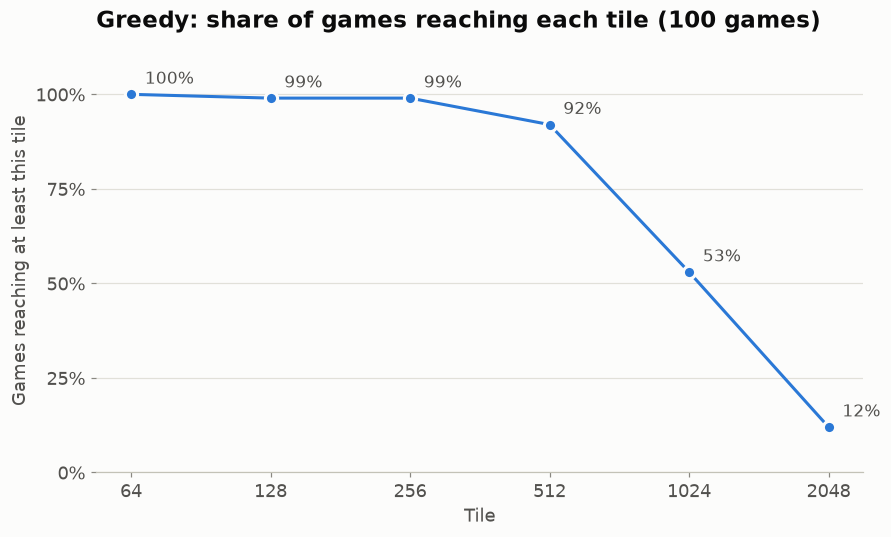

In [5]:
tiles = [2 ** k for k in range(6, 12)]  # 64 ... 2048
pct = [(games["max_tile"] >= t).mean() * 100 for t in tiles]
x = np.arange(len(tiles))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, pct, color=GREEDY, marker="o", markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
for xi, p in zip(x, pct):
    ax.annotate(f"{p:.0f}%", (xi, p), xytext=(9, 7), textcoords="offset points",
                ha="left", color=TEXT_2, fontsize=11)
ax.set_xticks(x, [str(t) for t in tiles])
ax.set_ylim(0, 112)
ax.set_yticks(range(0, 101, 25))
ax.yaxis.set_major_formatter(percent)
ax.set_xlabel("Tile")
ax.set_ylabel("Games reaching at least this tile")
ax.set_title(f"Greedy: share of games reaching each tile ({N_GAMES} games)")
save(fig, "fig1_tile_reach.png")
plt.show()

## Figure 2: Score distribution

How Greedy's final scores spread out across the 100 games.

Saved experiments/figures/fig2_score_distribution.png


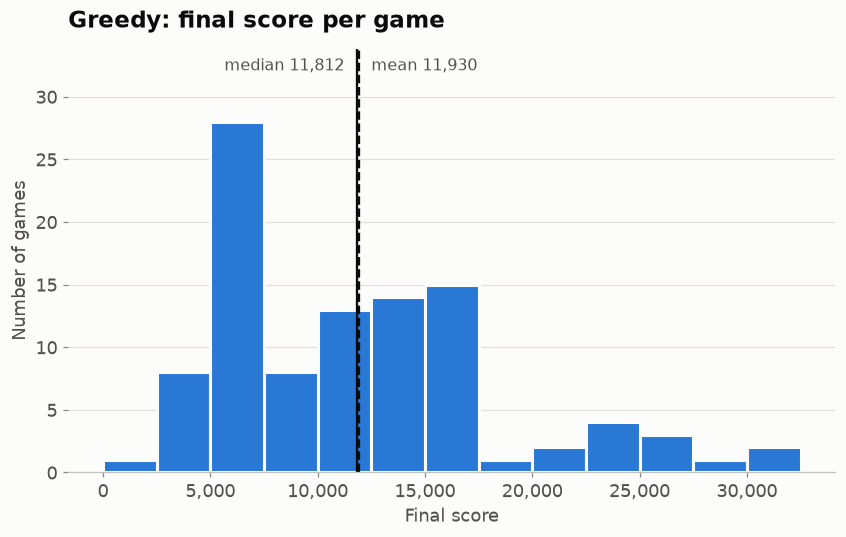

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.arange(0, games["score"].max() + 2500, 2500)
ax.hist(games["score"], bins=bins, color=GREEDY, edgecolor=SURFACE, linewidth=2)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)  # headroom for the labels
for value, name, offset in [(games["score"].median(), "median", -8), (games["score"].mean(), "mean", 8)]:
    ax.axvline(value, color=TEXT, linewidth=1.5, linestyle="--" if name == "mean" else "-")
    ax.annotate(f"{name} {value:,.0f}", (value, ax.get_ylim()[1]), xytext=(offset, -14),
                textcoords="offset points", ha="right" if offset < 0 else "left",
                color=TEXT_2, fontsize=10.5)
ax.xaxis.set_major_formatter(comma)
ax.set_xlabel("Final score")
ax.set_ylabel("Number of games")
ax.set_title("Greedy: final score per game")
save(fig, "fig2_score_distribution.png")
plt.show()

## Figure 3: Highest tile reached

Which tile each game ended on.

Saved experiments/figures/fig3_max_tile_distribution.png


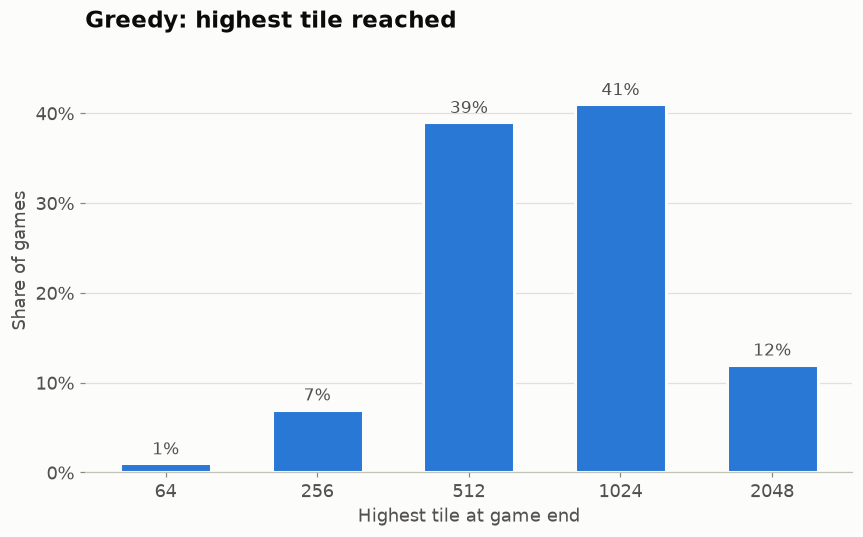

In [7]:
counts = games["max_tile"].value_counts().sort_index()
x = np.arange(len(counts))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, counts.values / N_GAMES * 100, width=0.6, color=GREEDY, edgecolor=SURFACE, linewidth=2)
for xi, c in zip(x, counts.values):
    ax.annotate(f"{c / N_GAMES * 100:.0f}%", (xi, c / N_GAMES * 100), xytext=(0, 6),
                textcoords="offset points", ha="center", color=TEXT_2, fontsize=11)
ax.set_xticks(x, [str(t) for t in counts.index])
ax.yaxis.set_major_formatter(percent)
ax.set_ylim(0, counts.max() / N_GAMES * 100 * 1.15)
ax.set_xlabel("Highest tile at game end")
ax.set_ylabel("Share of games")
ax.set_title("Greedy: highest tile reached")
save(fig, "fig3_max_tile_distribution.png")
plt.show()

## Figure 4: What does each heuristic feature contribute? (ablation)

Greedy is re-run with one feature switched off at a time (its weight set to 0). A big drop means that feature matters.

Saved experiments/figures/fig4_heuristic_ablation.png


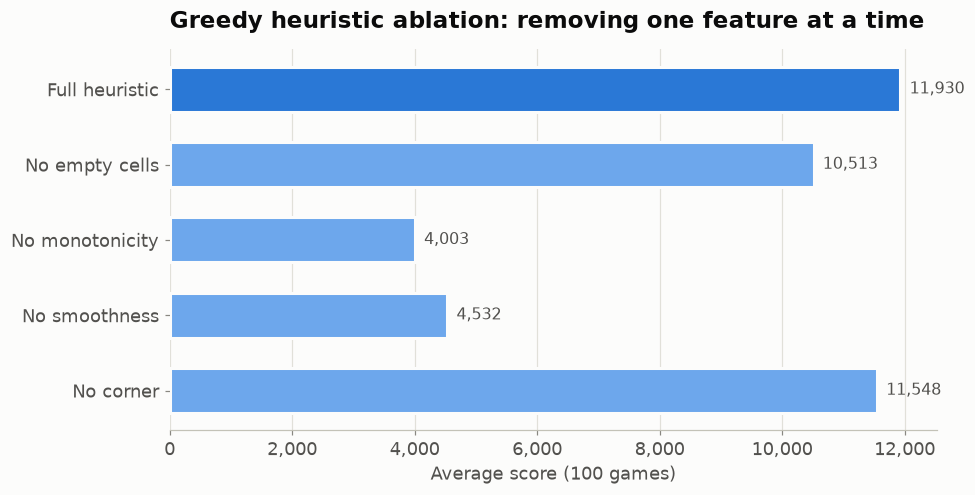

,variant,avg_score,reached_1024_pct,reached_2048_pct
0,Full heuristic,"11,930",53%,12%
1,No empty cells,"10,513",48%,9%
2,No monotonicity,"4,003",4%,0%
3,No smoothness,"4,532",1%,0%
4,No corner,"11,548",54%,7%


In [8]:
full = DEFAULT_WEIGHTS
variants = {
    "Full heuristic": full,
    "No empty cells": HeuristicWeights(0, full.monotonicity, full.smoothness, full.corner),
    "No monotonicity": HeuristicWeights(full.empty, 0, full.smoothness, full.corner),
    "No smoothness": HeuristicWeights(full.empty, full.monotonicity, 0, full.corner),
    "No corner": HeuristicWeights(full.empty, full.monotonicity, full.smoothness, 0),
}

rows = []
for variant, weights in variants.items():
    res = play_games(GreedyAgent(weights), SEEDS)
    rows.append({"variant": variant,
                 "avg_score": np.mean([r.score for r in res]),
                 "reached_1024_pct": np.mean([r.max_tile >= 1024 for r in res]) * 100,
                 "reached_2048_pct": np.mean([r.max_tile >= 2048 for r in res]) * 100})
ablation = pd.DataFrame(rows)
ablation.to_csv(os.path.join(RESULTS_DIR, "greedy_ablation.csv"), index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(ablation))[::-1]
bar_colors = [GREEDY if v == "Full heuristic" else BLUE_RAMP[2] for v in ablation["variant"]]
ax.barh(y, ablation["avg_score"], color=bar_colors, height=0.6, edgecolor=SURFACE, linewidth=2)
for yi, s in zip(y, ablation["avg_score"]):
    ax.annotate(f"{s:,.0f}", (s, yi), xytext=(6, 0), textcoords="offset points",
                va="center", color=TEXT_2, fontsize=10.5)
ax.set_yticks(y, ablation["variant"])
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.xaxis.set_major_formatter(comma)
ax.set_xlabel(f"Average score ({N_GAMES} games)")
ax.set_title("Greedy heuristic ablation: removing one feature at a time")
save(fig, "fig4_heuristic_ablation.png")
plt.show()
ablation.style.format({"avg_score": "{:,.0f}", "reached_1024_pct": "{:.0f}%", "reached_2048_pct": "{:.0f}%"})

## Figure 5: Weight sensitivity (smoothness × corner)

Average score as two weights vary, with the others held at their defaults. Darker is better. Uses seeds 1000+ so it doesn't reuse the evaluation games.

Saved experiments/figures/fig5_weight_sensitivity.png


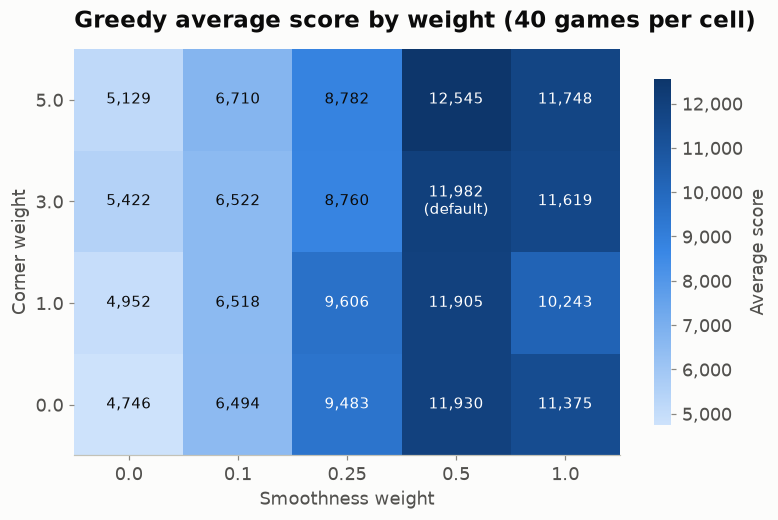

In [9]:
SWEEP_GAMES = 40
SWEEP_SEEDS = list(range(1000, 1000 + SWEEP_GAMES))
smooth_values = [0.0, 0.1, 0.25, 0.5, 1.0]
corner_values = [0.0, 1.0, 3.0, 5.0]

grid = np.zeros((len(corner_values), len(smooth_values)))
for i, c in enumerate(corner_values):
    for j, s in enumerate(smooth_values):
        w = HeuristicWeights(full.empty, full.monotonicity, s, c)
        grid[i, j] = np.mean([r.score for r in play_games(GreedyAgent(w), SWEEP_SEEDS)])

cmap = LinearSegmentedColormap.from_list("blue_seq", BLUE_RAMP)
fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(grid, cmap=cmap, aspect="auto", origin="lower")
ax.grid(False)
ax.set_xticks(range(len(smooth_values)), [str(v) for v in smooth_values])
ax.set_yticks(range(len(corner_values)), [str(v) for v in corner_values])
ax.set_xlabel("Smoothness weight")
ax.set_ylabel("Corner weight")
threshold = grid.min() + 0.55 * (grid.max() - grid.min())
for i in range(len(corner_values)):
    for j in range(len(smooth_values)):
        is_default = corner_values[i] == full.corner and smooth_values[j] == full.smoothness
        ax.text(j, i, f"{grid[i, j]:,.0f}" + ("\n(default)" if is_default else ""),
                ha="center", va="center", fontsize=9.5,
                color="#ffffff" if grid[i, j] > threshold else TEXT)
cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.outline.set_visible(False)
cbar.ax.yaxis.set_major_formatter(comma)
cbar.set_label("Average score", color=TEXT_2)
ax.set_title(f"Greedy average score by weight ({SWEEP_GAMES} games per cell)")
save(fig, "fig5_weight_sensitivity.png")
plt.show()

## Demo: Greedy's best game

Score over time and the final board, for the demo slide.

Saved experiments/figures/fig6_demo_best_game.png


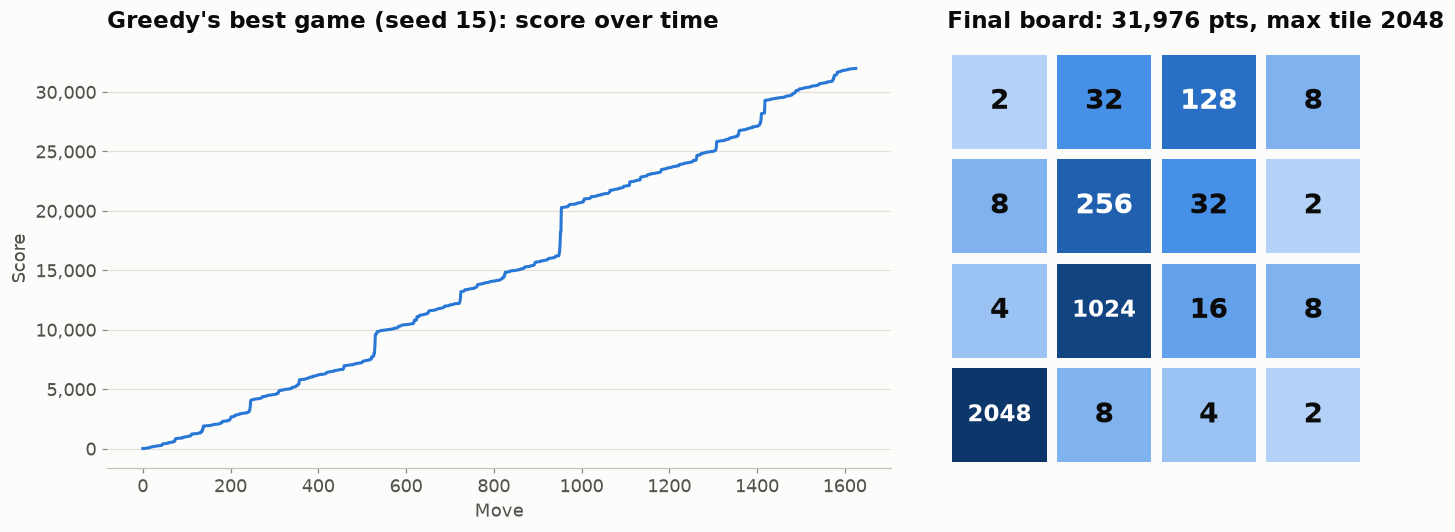

+------+------+------+------+
|  2   |  32  | 128  |  8   |
+------+------+------+------+
|  8   | 256  |  32  |  2   |
+------+------+------+------+
|  4   | 1024 |  16  |  8   |
+------+------+------+------+
| 2048 |  8   |  4   |  2   |
+------+------+------+------+


In [10]:
def replay(agent, seed):
    """Play one game, recording the score after every move."""
    game = Game(seed=seed)
    history = [game.score]
    while not game.is_over():
        game.step(agent.choose_move(game.board))
        history.append(game.score)
    return game, history


def draw_board(ax, board, title):
    n = len(board)
    cmap = LinearSegmentedColormap.from_list("tiles", BLUE_RAMP)
    top = max(11, max(max(r) for r in board).bit_length() - 1)
    for r in range(n):
        for c in range(n):
            v = board[r][c]
            level = (math.log2(v) / top) if v else None
            face = cmap(level) if v else "#efeee9"
            ax.add_patch(plt.Rectangle((c + 0.05, n - r - 0.95), 0.9, 0.9, facecolor=face, edgecolor="none"))
            if v:
                ax.text(c + 0.5, n - r - 0.5, str(v), ha="center", va="center",
                        fontsize=18 if v < 1000 else 15, fontweight="bold",
                        color="#ffffff" if level > 0.5 else TEXT)
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)


best_seed = int(games.loc[games["score"].idxmax(), "seed"])
final_game, history = replay(GreedyAgent(), best_seed)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(range(len(history)), history, color=GREEDY)
ax1.yaxis.set_major_formatter(comma)
ax1.set_xlabel("Move")
ax1.set_ylabel("Score")
ax1.set_title(f"Greedy's best game (seed {best_seed}): score over time")
draw_board(ax2, final_game.board, f"Final board: {final_game.score:,} pts, max tile {final_game.max_tile()}")
fig.tight_layout()
save(fig, "fig6_demo_best_game.png")
plt.show()
print(format_board(final_game.board))

# Part 2: What if the tiles fight back?

In normal 2048, new tiles appear at random. Here an AI **spawner** decides where every new tile goes, using adversarial search:

- **Villain:** places each tile where it does the most damage to the player.
- **Helper:** places each tile where it helps the player most.
- **Random:** the normal game (reproduces the results above exactly).

The spawner searches ahead `depth` player turns, models the player as greedy, and scores positions with the shared heuristic. So the villain knows exactly how Greedy thinks. Greedy plays the same 100 seeded games against each spawner.

Results come from `python3 -m experiments.spawner_experiment` (about 15 minutes, mostly helper games). The notebook runs it if the CSV is missing.

In [11]:
import subprocess

from spawners import HelperSpawner, RandomSpawner, VillainSpawner, play_game_with_spawner

SPAWNER_CSV = os.path.join(RESULTS_DIR, "greedy_vs_spawners.csv")
if FORCE_RERUN or not os.path.exists(SPAWNER_CSV):
    subprocess.run([sys.executable, "-m", "experiments.spawner_experiment", "--games", str(N_GAMES)],
                   cwd=REPO_ROOT, check=True)

VILLAIN, NEUTRAL, HELPER = "#e34948", "#52514e", "#2a78d6"
VILLAIN_LIGHT, HELPER_LIGHT = "#f0a3a2", "#9ec5f4"

spawn = pd.read_csv(SPAWNER_CSV)
spawn["condition"] = spawn.apply(
    lambda r: "Random (normal game)" if r.spawner == "random" else f"{r.spawner.title()} (depth {r.depth})", axis=1)
ORDER = ["Villain (depth 2)", "Villain (depth 1)", "Random (normal game)", "Helper (depth 1)", "Helper (depth 2)"]
COND_COLORS = {"Villain (depth 2)": VILLAIN, "Villain (depth 1)": VILLAIN_LIGHT,
               "Random (normal game)": NEUTRAL, "Helper (depth 1)": HELPER_LIGHT, "Helper (depth 2)": HELPER}
order = [c for c in ORDER if c in set(spawn["condition"])]

spawn_summary = spawn.groupby("condition").agg(
    games=("score", "size"),
    distinct_games=("score", "nunique"),
    avg_score=("score", "mean"),
    median_score=("score", "median"),
    reached_512=("max_tile", lambda t: (t >= 512).mean() * 100),
    reached_2048=("max_tile", lambda t: (t >= 2048).mean() * 100),
    avg_moves=("moves", "mean"),
    capped=("capped", "sum"),
    ms_per_spawn=("ms_per_spawn", "mean"),
).loc[order]
spawn_summary.to_csv(os.path.join(RESULTS_DIR, "greedy_vs_spawners_summary.csv"))
spawn_summary.style.format({"avg_score": "{:,.0f}", "median_score": "{:,.0f}", "reached_512": "{:.0f}%",
                            "reached_2048": "{:.0f}%", "avg_moves": "{:,.0f}", "ms_per_spawn": "{:.2f}"})

,games,distinct_games,avg_score,median_score,reached_512,reached_2048,avg_moves,capped,ms_per_spawn
condition,,,,,,,,,
Villain (depth 2),100,10,356,364,0%,0%,45,0,7.25
Villain (depth 1),100,12,765,610,0%,0%,78,0,0.54
Random (normal game),100,99,"11,930","11,812",92%,12%,714,0,0.00
Helper (depth 1),100,2,"11,780","11,780",100%,0%,484,0,0.64
Helper (depth 2),100,2,"33,484","33,484",100%,100%,"1,159",0,7.26


## Figure 7: Same agent, three different opponents

Greedy never changes. Only the tile spawner does.

Saved experiments/figures/fig7_spawner_scores.png


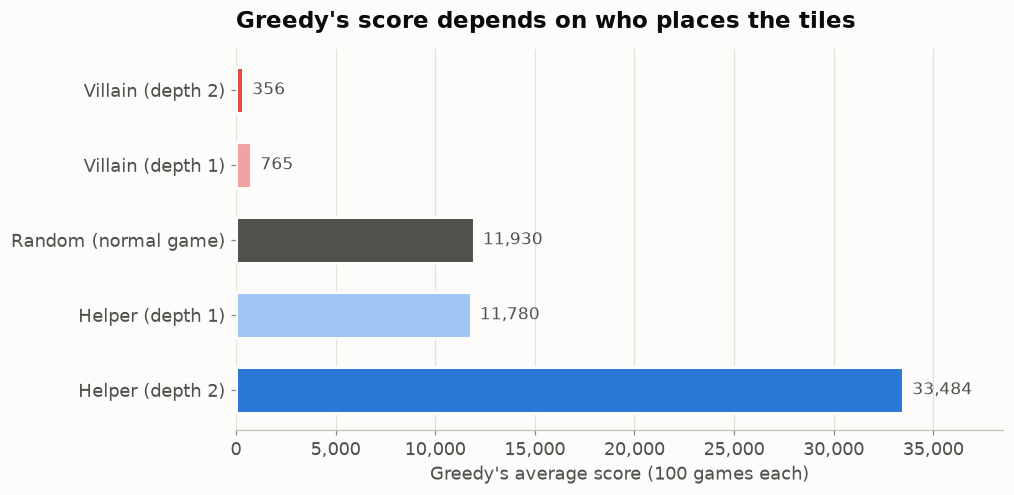

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(order))[::-1]
means = [spawn_summary.loc[c, "avg_score"] for c in order]
ax.barh(y, means, color=[COND_COLORS[c] for c in order], height=0.62, edgecolor=SURFACE, linewidth=2)
for yi, m in zip(y, means):
    ax.annotate(f"{m:,.0f}", (m, yi), xytext=(6, 0), textcoords="offset points",
                va="center", color=TEXT_2, fontsize=11)
ax.set_yticks(y, order)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.xaxis.set_major_formatter(comma)
ax.set_xlim(0, max(means) * 1.15)
ax.set_xlabel(f"Greedy's average score ({N_GAMES} games each)")
ax.set_title("Greedy's score depends on who places the tiles")
save(fig, "fig7_spawner_scores.png")
plt.show()

## Figure 8: How far Greedy gets against each spawner

Saved experiments/figures/fig8_spawner_tile_reach.png


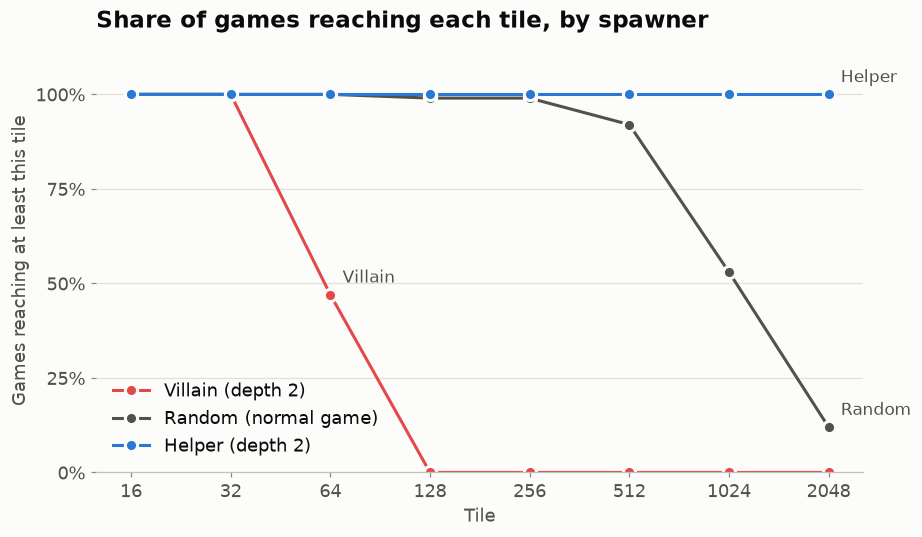

In [13]:
tiles = [2 ** k for k in range(4, 12)]  # 16 ... 2048
x = np.arange(len(tiles))
fig, ax = plt.subplots(figsize=(9, 5))
for cond in ["Villain (depth 2)", "Random (normal game)", "Helper (depth 2)"]:
    if cond not in order:
        continue
    sub = spawn[spawn["condition"] == cond]
    pct = [(sub["max_tile"] >= t).mean() * 100 for t in tiles]
    ax.plot(x, pct, color=COND_COLORS[cond], marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=cond)
    last = max((i for i, p in enumerate(pct) if p > 0), default=0)
    ax.annotate(cond.split(" (")[0], (x[last], pct[last]), xytext=(8, 8), textcoords="offset points",
                color=TEXT_2, fontsize=11)
ax.set_xticks(x, [str(t) for t in tiles])
ax.set_ylim(0, 112)
ax.set_yticks(range(0, 101, 25))
ax.yaxis.set_major_formatter(percent)
ax.set_xlabel("Tile")
ax.set_ylabel("Games reaching at least this tile")
ax.set_title("Share of games reaching each tile, by spawner")
ax.legend(loc="lower left")
save(fig, "fig8_spawner_tile_reach.png")
plt.show()

## Figure 9: The same starting position, three endings

Greedy plays seed 0 against each spawner. The starting tiles are identical; only the tile placement differs.

Saved experiments/figures/fig9_spawner_final_boards.png


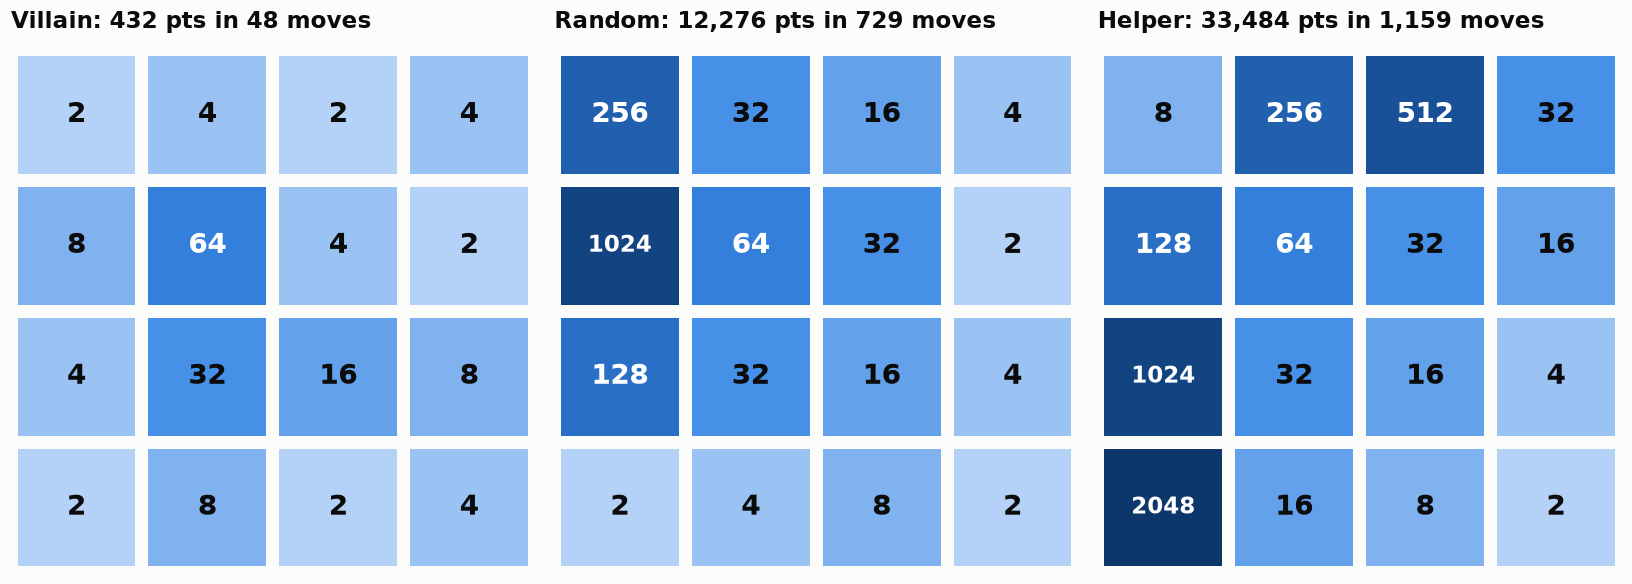

In [14]:
matchups = [("Villain", VillainSpawner(depth=2)), ("Random", RandomSpawner()), ("Helper", HelperSpawner(depth=2))]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
for ax, (name, spawner) in zip(axes, matchups):
    r = play_game_with_spawner(GreedyAgent(), spawner, seed=0, max_moves=10000)
    draw_board(ax, r.final_board, f"{name}: {r.score:,} pts in {r.moves:,} moves")
fig.tight_layout()
save(fig, "fig9_spawner_final_boards.png")
plt.show()

## Notes for the paper and slides

- Results use seeds 0–99. The heuristic weights were tuned on seeds 1000–1059 and checked on held-out seeds 5000–5099, so the evaluation games were never used for tuning.
- Time per move depends on the machine, so report the hardware alongside timing results. Scores are deterministic for a given seed.
- Spawner caveat: the villain and helper model the player with the same heuristic Greedy uses, so against Greedy they have a perfect model of their opponent. Against humans or other agents they are using a proxy.
- With the villain or helper, the game has no randomness after the two starting tiles, and different starts quickly converge to the same few games. `distinct_games` in the summary table counts distinct final scores, which is the honest sample size for those conditions. The collapse is itself a result: the spawner removes nearly all of the luck.
- The villain may choose 2 or 4 freely at every spawn, unlike the normal 90/10 rule. That is part of its power and should be stated when reporting results.